In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from upconversion_models.anderson_suyver import AndersonModel as M
# from upconversion_models.anderson import AndersonModel as M
from upconversion_models.jablonski_patch import (
    Simulator,
    SteadyState,
    EmissionTransform,
)
from upconversion_models.utils import k,hc
from poincare.solvers import LSODA
from pint import get_application_registry
u = get_application_registry()

In [6]:
df_table1 = pd.read_csv('../sources/suyver2005_digitized/table1.csv')
df_table1.head()

,i,energy_cm-1,transition,p_i,f_i_10mW_pct,f_i_100mW_pct,f_i_600mW_pct,R_i_10mW_pct,R_i_100mW_pct,R_i_600mW_pct
0,1,6500,Er 4I13/2 -> 4I15/2,1,3.0,13.0,18.0,2.9,10.8,13.4
1,2,10000,Yb 2F5/2 -> 2F7/2 + Er 4I11/2 -> 4I15/2,1,93.0,68.0,48.0,90.3,56.8,35.9
2,3,11800,Er 4S3/2 -> 4I13/2,2,0.6,1.7,2.1,1.2,2.8,3.1
3,4,15000,Er 4F9/2 -> 4I15/2,2,0.5,7.9,16.0,1.0,13.2,24.0
4,5,18200 / 18800,Er 4S3/2 -> 4I15/2 + Er 2H11/2 -> 4I15/2,2,2.6,9.5,15.0,4.9,15.8,22.5


In [7]:
from pathlib import Path

suyver_dir = Path('../sources/suyver2005_digitized')

def load_suyver(pattern):
    return pd.concat(
        [pd.read_csv(f).assign(curve="_".join(f.stem.split('_')[:2])) for f in sorted(suyver_dir.glob(pattern))],
        ignore_index=True,
    )

df_points = load_suyver('fig3*_points.csv')
df_points['T_K'] = df_points['T_K'].round().astype(int)
df_points = df_points.pivot_table(index='T_K', columns='curve', values='photon_flux_counts_per_s')

df_fits = load_suyver('fig3*_fit_*.csv').pivot_table(index='T_K', columns='curve', values='photon_flux_counts_per_s')
df_fits

curve,fig3a_6500h,fig3a_6500l,fig3b_10000,fig3c_18200,fig3d_24000
T_K,,,,,
9.94,NaN,186.5,NaN,NaN,NaN
10.01,NaN,NaN,131900.0,NaN,NaN
10.63,NaN,NaN,NaN,4.050,NaN
10.87,NaN,287.9,NaN,NaN,NaN
11.12,NaN,NaN,NaN,6.805,NaN
...,...,...,...,...,...
199.54,NaN,NaN,NaN,NaN,34150.0
199.93,17190.0,NaN,NaN,NaN,NaN
199.94,NaN,NaN,36210.0,NaN,NaN


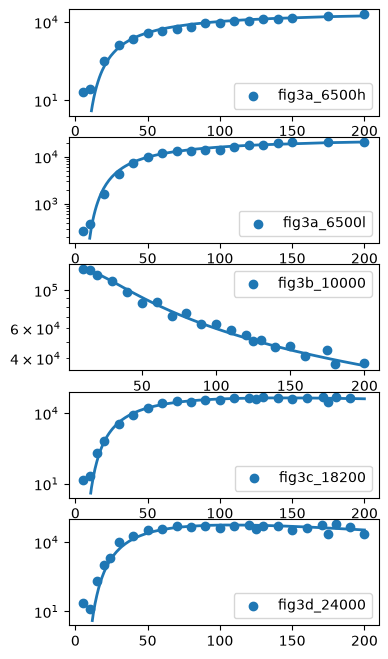

In [8]:
fig, axs = plt.subplots(len(df_points.columns), figsize=(4,8))

for (n,s), ax in zip(df_points.items(), axs):
    ax.scatter(s.index, s, label=n)

    f = df_fits[n]
    ax.plot(f.dropna(), lw=2)
    
    ax.set_yscale('log')
    ax.legend()

In [ ]:
p_map = {
    "fig3a_6500l": 1,
    "fig3a_6500h": 2,
    "fig3c_18200": 2,
    "fig3b_10000": 1,
    "fig3d_24000": 3,
}

In [10]:
sim = (
    Simulator(M())
    .with_transform(EmissionTransform(kind="emission"), append=True)
    .with_values({M.energy_flux: 5 * u.W / u.cm**2})
    .with_solver(LSODA(rtol=1e-8, atol=1e-16))
)
steady = SteadyState()

In [11]:
energy_flux_values = np.logspace(-1, 4) * u.W / u.cm**2
ds = steady.sweep(sim, variable=M.energy_flux, values=energy_flux_values)
df = ds.pint.dequantify().to_dataframe()
df.head()

,line_rad,line_rad20,line_rad81,line_rad82,line_rad83,line_rad85,line_rad61,line_rad62,line_rad63,line_rad51,...,Er5,Er6,Er7,Er8,Er9,Yb1,Yb20,Yb21,time,event
energy_flux,,,,,,,,,,,,,,,,,,,,,
0.100000,0.000211,0.000254,2.175656e-09,2.284439e-09,7.614797e-10,2.175656e-10,0.000002,5.568648e-07,1.113730e-07,6.997806e-08,...,3.813310e-11,1.475139e-09,1.320226e-11,2.334395e-12,6.009881e-14,0.170999,6.460884e-07,5.358727e-07,0.171325,0
0.126486,0.000265,0.000320,4.340106e-09,4.557111e-09,1.519037e-09,4.340106e-10,0.000002,8.812257e-07,1.762451e-07,1.250153e-07,...,6.812454e-11,2.334373e-09,2.095177e-11,4.656766e-12,1.197299e-13,0.170999,8.133758e-07,6.746226e-07,0.170627,0
0.159986,0.000333,0.000402,8.627145e-09,9.058503e-09,3.019501e-09,8.627145e-10,0.000004,1.390752e-06,2.781504e-07,2.252782e-07,...,1.227607e-10,3.684111e-09,3.318361e-11,9.256594e-12,2.376068e-13,0.170998,1.022786e-06,8.483094e-07,0.168602,0
0.202359,0.000419,0.000505,1.707415e-08,1.792785e-08,5.975952e-09,1.707415e-09,0.000006,2.187618e-06,4.375235e-07,4.087638e-07,...,2.227474e-10,5.795013e-09,5.242769e-11,1.831990e-11,4.693035e-13,0.170998,1.284273e-06,1.065190e-06,0.176698,0
0.255955,0.000525,0.000633,3.361256e-08,3.529319e-08,1.176440e-08,3.361256e-09,0.000010,3.427205e-06,6.854410e-07,7.451899e-07,...,4.060759e-10,9.078688e-09,8.258504e-11,3.606498e-11,9.215960e-13,0.170997,1.609812e-06,1.335195e-06,0.175456,0


In [12]:
line_map = {
    1: ["line_rad2"],
    2: ["line_rad","line_rad20", "line_rad31"],
    3: ["line_rad62"],
    4: ["line_rad51"],
    5: ["line_rad61"],
    6: ["line_rad81"]
} 

In [13]:
trans_df = pd.DataFrame(index=df.index)
for i, lines in line_map.items():
    trans_df[f'trans_{i}'] = df[lines].sum(axis=1)

trans_df['total'] = trans_df.sum(axis=1)

f_df = pd.DataFrame(index=trans_df.index)
for i in range(1,7):
    f_df[f'f_{i}'] = trans_df[f'trans_{i}'] / trans_df['total']

f_df.head()

,f_1,f_2,f_3,f_4,f_5,f_6
energy_flux,,,,,,
0.100000,0.118804,0.877433,0.000957,0.000120,0.002681,0.000004
0.126486,0.122946,0.872331,0.001197,0.000170,0.003350,0.000006
0.159986,0.128021,0.866063,0.001491,0.000242,0.004175,0.000009
0.202359,0.134188,0.858417,0.001851,0.000346,0.005184,0.000014
0.255955,0.141608,0.849174,0.002289,0.000498,0.006409,0.000022


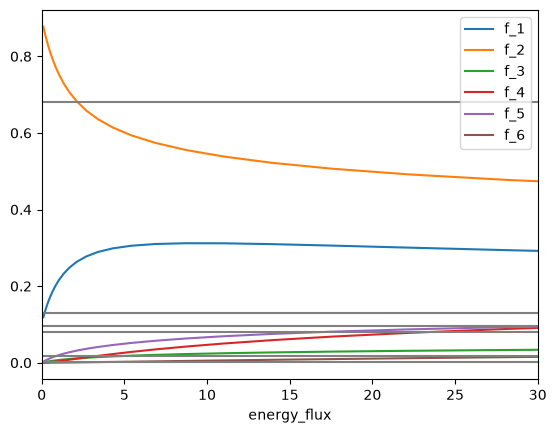

In [15]:
f_df.plot()

mW100 = df_table1['f_i_100mW_pct'].to_numpy()/100
for i in range(6):
    plt.axhline(mW100[i], color='gray', label=f"{i+1}")
plt.xlim(0,30)
plt.show()

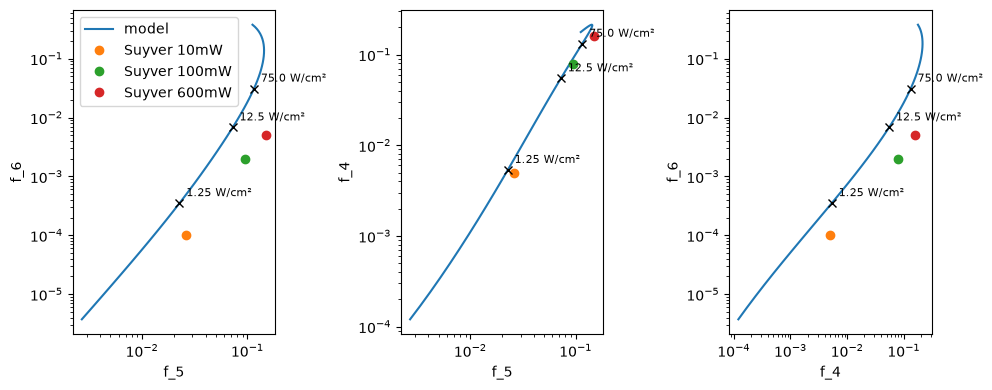

In [16]:
# f_i vs f_j: irradiance drops out, so no mW -> W/cm² conversion is needed
pairs = [(5, 6), (5, 4), (4,6)]
powers = ["10mW", "100mW", "600mW"]
base = 1.25
marked_irradiances = [base, base * 10, base * 60]  # W/cm², where to mark the model curve

log_I = np.log10(f_df.index.to_numpy())

fig, axes = plt.subplots(1, len(pairs), figsize=(10, 4))
for ax, (i, j) in zip(axes, pairs):
    ax.plot(f_df[f"f_{i}"], f_df[f"f_{j}"], "-", label="model")
    for p in powers:
        fi = df_table1[f"f_i_{p}_pct"].iloc[i - 1] / 100
        fj = df_table1[f"f_i_{p}_pct"].iloc[j - 1] / 100
        ax.plot(fi, fj, "o", label=f"Suyver {p}")
    for I in marked_irradiances:
        fi = np.interp(np.log10(I), log_I, f_df[f"f_{i}"])
        fj = np.interp(np.log10(I), log_I, f_df[f"f_{j}"])
        ax.plot(fi, fj, "kx")
        ax.annotate(f"{I} W/cm²", (fi, fj), textcoords="offset points", xytext=(5, 5), fontsize=8)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(f"f_{i}")
    ax.set_ylabel(f"f_{j}")
axes[0].legend()
plt.tight_layout()
plt.show()

In [48]:
Ts = np.linspace(10, 200, 20) * u.K
ds = steady.sweep(
    sim.with_values({M.energy_flux: 0.01 * u.W / u.cm**2, M.E_q: 284 / u.cm}),
    variable=M.T,
    values=Ts,
).to_dataframe()

In [ ]:
def suyver_eq3(T, I_inf, E_q=85., *, p):
    """Suyver 2005 Eq. (3) with σ_Yb(T) ∝ exp(-k_B·T/E_q).

    T in K, dE and E_q in cm⁻¹.
    """
    T = np.asarray(T, float) * u.K
    Eq = E_q / u.cm
    dE = 39.0 / u.cm
    sigma_Yb = np.exp((-k * T / (Eq * hc)).to(""))
    return (I_inf * np.exp((-p * dE * hc / (k * T)).to("")) * sigma_Yb**p).magnitude


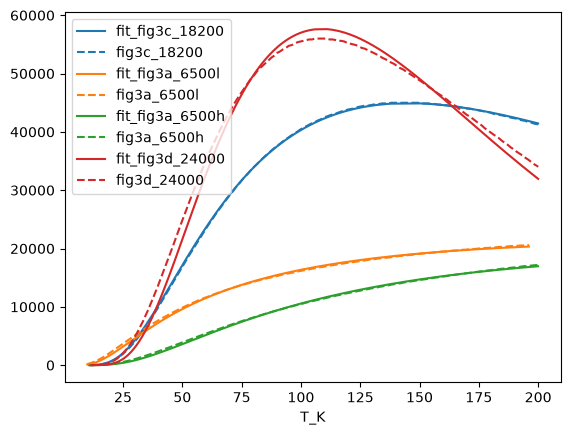

In [ ]:
from scipy.optimize import curve_fit
from functools import partial
p0s = [
    [10e4, 85],
    [10e4, 85],
    [10e4, 85],
    [10e4, 200]
    ]
for i, (n, s) in enumerate(
    df_fits[
        [
            "fig3c_18200",
            "fig3a_6500l",
            "fig3a_6500h",
            "fig3d_24000",
        ]
    ].items()
):
    s = s.dropna()
    x = s.index.to_numpy()
    f = partial(suyver_eq3, p=p_map[str(n)])

    popt, cov = curve_fit(
        f,
        x,
        s.to_numpy(),
        p0=p0s[i],
    )
    plt.plot(x, f(x, *popt), label=f"fit_{n}", color=f"C{i}")
    s.plot(ls="--", color=f"C{i}")
    
plt.legend()

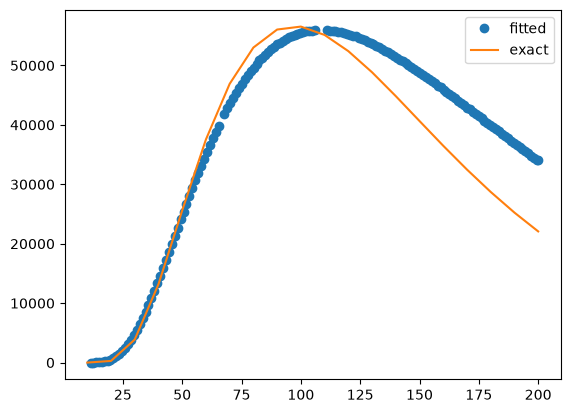

In [105]:
# ds.plot(y="line_rad61")

plt.plot(df_fits["fig3d_24000"].dropna(), "o", label="fitted")

plt.plot(
    Ts,
    suyver_eq3(
        Ts.magnitude,
        1.8090361e06,
        E_q=117,
        p=3,
    ),
    label="exact",
)

plt.legend()
plt.show()